In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem

df = pd.read_pickle(r'Data and variables\dippr_db_mol_generated.pkl')
df = df[['ChemID','mol','T','TC','Surface_tension']]
df

,ChemID,mol,T,TC,Surface_tension
0,1501,<rdkit.Chem.rdchem.Mol object at 0x000001DFB31...,293.149994,556.6,26.75
1,1501,<rdkit.Chem.rdchem.Mol object at 0x000001DFB31...,298.149994,556.6,26.15
2,1501,<rdkit.Chem.rdchem.Mol object at 0x000001DFB31...,293.149994,556.6,26.66
3,1501,<rdkit.Chem.rdchem.Mol object at 0x000001DFB31...,288.149994,556.6,27.65
4,1501,<rdkit.Chem.rdchem.Mol object at 0x000001DFB31...,298.149994,556.6,26.43
...,...,...,...,...,...
25644,350,<rdkit.Chem.rdchem.Mol object at 0x000001DFBB7...,293.149994,834.2,31.70
25645,21381,<rdkit.Chem.rdchem.Mol object at 0x000001DFBB7...,499.850006,779.0,23.50
25646,21381,<rdkit.Chem.rdchem.Mol object at 0x000001DFBB8...,460.950012,779.0,28.00
25647,21381,<rdkit.Chem.rdchem.Mol object at 0x000001DFBB7...,455.350006,779.0,28.80


In [2]:
df.describe()

,ChemID,T,TC,Surface_tension
count,25649.000000,25649.000000,25630.000000,25649.000000
mean,2663.082810,374.595205,641.405299,22.192065
std,3826.475359,114.162652,95.720451,11.496106
min,6.000000,108.019997,396.500000,0.000000
25%,1019.000000,295.950012,569.000000,13.800000
50%,1587.000000,339.670013,637.900000,22.250000
75%,3102.000000,443.000000,700.000000,29.200000
max,27872.000000,936.250000,1644.000000,111.470000


In [3]:
df = df[df['Surface_tension']>0]
df['log_sigma'] = np.log(df['Surface_tension'])
df = df[df['log_sigma']>0]
df['log_tau'] = np.log(1-(df['T']/df['TC']))
df.dropna(inplace=True)

c:\Users\erfer.LUBRIZOL\OneDrive - Lubrizol\Documents\Git Repositories\Computational Modeling\.venv\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

reg = LinearRegression()
X = df[['log_tau']]
y = df['log_sigma']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

reg.fit(X_train, y_train)
print(reg.score(X_train, y_train))
print(reg.score(X_test, y_test))

0.8998035772156624
0.8970344786477575


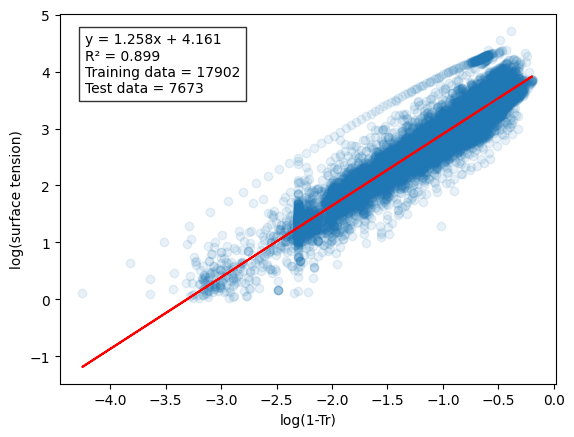

In [5]:
import matplotlib.pyplot as plt

# Predictions
y_pred = reg.predict(X_test)

# Metrics
coef = reg.coef_[0]
intercept = reg.intercept_
r2 = reg.score(X, df["log_sigma"])

# Plot
plt.scatter(df["log_tau"], df["log_sigma"], alpha=0.1)
plt.plot(X_test, y_pred, color='red')

plt.xlabel("log(1-Tr)")
plt.ylabel("log(surface tension)")

n = len(df)

plt.text(
    0.05, 0.95,
    f'y = {coef:.3f}x + {intercept:.3f}\n'
    f'R² = {r2:.3f}\n'
    f'Training data = {len(X_train)}\n'
    f'Test data = {len(X_test)}',
    transform=plt.gca().transAxes,
    va='top',
    bbox=dict(facecolor='white', alpha=0.8)
)
plt.show()

In [22]:
np.exp(intercept)

np.float64(63.92444289319823)

In [6]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, train_size=.7, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=df["ChemID"]))

X = df[['log_tau']]
y = df['log_sigma']

X_train = X.iloc[train_idx].copy()
y_train = y.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_test = y.iloc[test_idx].copy()

reg.fit(X_train, y_train)
print(reg.score(X_train, y_train))
print(reg.score(X_test, y_test))

0.9060177715355491
0.8810339564468554


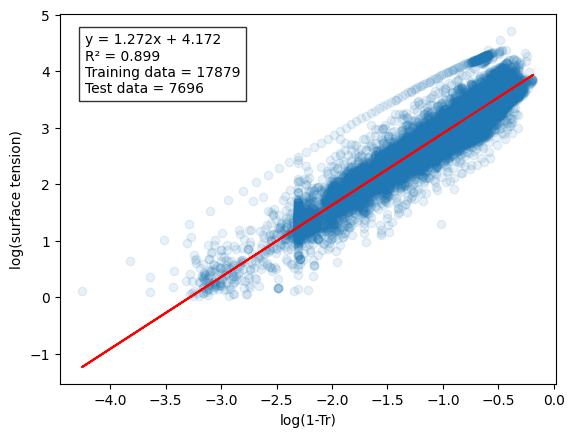

In [7]:
import matplotlib.pyplot as plt

# Predictions
y_pred = reg.predict(X_test)

# Metrics
coef = reg.coef_[0]
intercept = reg.intercept_
r2 = reg.score(X, df["log_sigma"])

# Plot
plt.scatter(df["log_tau"], df["log_sigma"], alpha=0.1)
plt.plot(X_test, y_pred, color='red')

plt.xlabel("log(1-Tr)")
plt.ylabel("log(surface tension)")

n = len(df)

plt.text(
    0.05, 0.95,
    f'y = {coef:.3f}x + {intercept:.3f}\n'
    f'R² = {r2:.3f}\n'
    f'Training data = {len(X_train)}\n'
    f'Test data = {len(X_test)}',
    transform=plt.gca().transAxes,
    va='top',
    bbox=dict(facecolor='white', alpha=0.8)
)
plt.show()